In [1]:
import datetime as dt
import sys
import time
from pathlib import Path

import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from utilities.preprocessor import *
from utilities.values import *

data_dir = '../data/'
model_dir = '../models/'

In [2]:
# read the dataset with weather features
full_features_df = pd.read_csv(data_dir + 'intermediate_processing/full_features.csv')

# use Jan - Dec 2020 only, so that we have a full year's weather data to analyse.
# the test set is not used, meaning it doesn't influence which features we keep
train_df = full_features_df[full_features_df[DATE] <= '2020-12-31']

# the features
weather_cols = [
    TEMPERATURE, RAIN, SNOW_DEPTH, SNOWFALL, CLOUD_COVER_LOW, CLOUD_COVER_MID, CLOUD_COVER_HIGH, 
    CLOUD_COVER, RELATIVE_HUMIDITY, PRECIPITATION, WIND_SPEED, WIND_GUSTS,
]
Y_column = NUM_RENTALS

# average the weather across stations and add up the rentals
hourly_df = (
    train_df
    .groupby([DATE, HOUR_OF_DAY, DAY_OF_WEEK])
    .agg({**{col: 'mean' for col in weather_cols}, Y_column: 'sum'})
    .reset_index()
)

### 1. Correlation between weather features

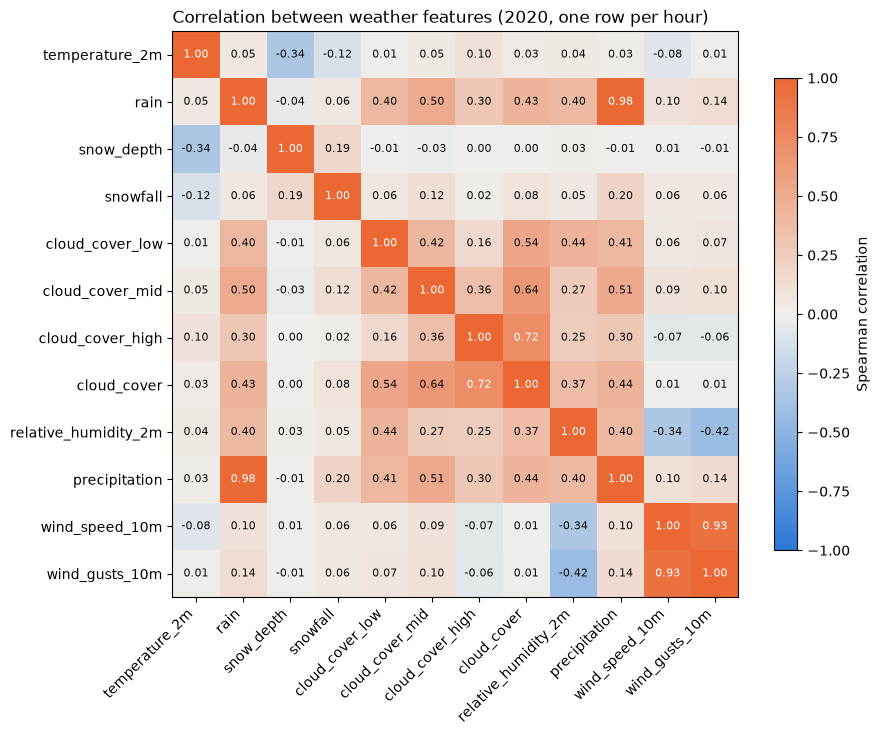

In [3]:
# how strongly each pair of weather features moves together
# Spearman correlation (rank-based), since several features are skewed or mostly zero
correlation = hourly_df[weather_cols].corr(method = 'spearman')

# blue = negative, grey = no relationship, orange = positive
diverging = LinearSegmentedColormap.from_list('diverging', ['#2a78d6', '#f0efec', '#eb6834'])

fig, ax = plt.subplots(figsize = (9, 7.5))
image = ax.imshow(correlation, cmap = diverging, vmin = -1, vmax = 1)
ax.set_xticks(range(len(weather_cols)), weather_cols, rotation = 45, ha = 'right')
ax.set_yticks(range(len(weather_cols)), weather_cols)
for i in range(len(weather_cols)):
    for j in range(len(weather_cols)):
        value = correlation.iloc[i, j]
        ax.text(j, i, f'{value:.2f}', ha = 'center', va = 'center', fontsize = 8,
                color = 'white' if abs(value) > 0.7 else '#0b0b0b')
fig.colorbar(image, ax = ax, shrink = 0.8, label = 'Spearman correlation')
ax.set_title('Correlation between weather features (2020, one row per hour)', loc = 'left')
plt.tight_layout()
plt.show()

#### Key findings:

##### 1. Rain, snow and precipitation

Features:
- `rain`: liquid rain that fell in the hour (mm)
- `snowfall`: new snow that fell in the hour (cm)
- `precipitation`: everything that fell in the hour, i.e. rain + snowfall, with snow converted to its water equivalent (mm)
- `snow_depth`: snow lying on the ground (m)

Why we keep only `precipitation` and `snow_depth` only:
- `precipitation` = `rain` + `snowfall`, so it already contains the information in both.
- `snow_depth` is different from the other three: It captures conditions that precipitation cannot (e.g. snow that stays on the ground for days after a storm)

##### 2. Wind speed and wind gusts

Features:
- `wind_speed_10m`: average wind speed 10 m above the ground during the hour (km/h)
- `wind_gusts_10m`: strongest gust 10 m above the ground during the hour (km/h)

Why we keep only `wind_speed_10m`:
- The two features are highly correlated (correlation = 0.93).
- The average wind speed is less prone to extremes than wind gusts. 

##### 3. Cloud cover

Features:
- `cloud_cover_low`: % of the sky covered by low clouds (up to about 2 km)
- `cloud_cover_mid`: % of the sky covered by mid-level clouds (about 2–6 km)
- `cloud_cover_high`: % of the sky covered by high clouds (above about 6 km)
- `cloud_cover`: % of the sky covered by any cloud, i.e. the three layers combined (overlapping layers are only counted once)

Why we keep only `cloud_cover` and `cloud_cover_mid`:
- `cloud_cover` already combines the three layers, so it captures how overcast the sky is overall.
- `cloud_cover_mid` Mid-level clouds are the ones that tend to bring rain.

In [4]:
# drop the ones we dont need anymore
dropped_columns = [RAIN, SNOWFALL, WIND_GUSTS, CLOUD_COVER_LOW, CLOUD_COVER_HIGH]
weather_cols = [col for col in weather_cols if col not in dropped_columns]

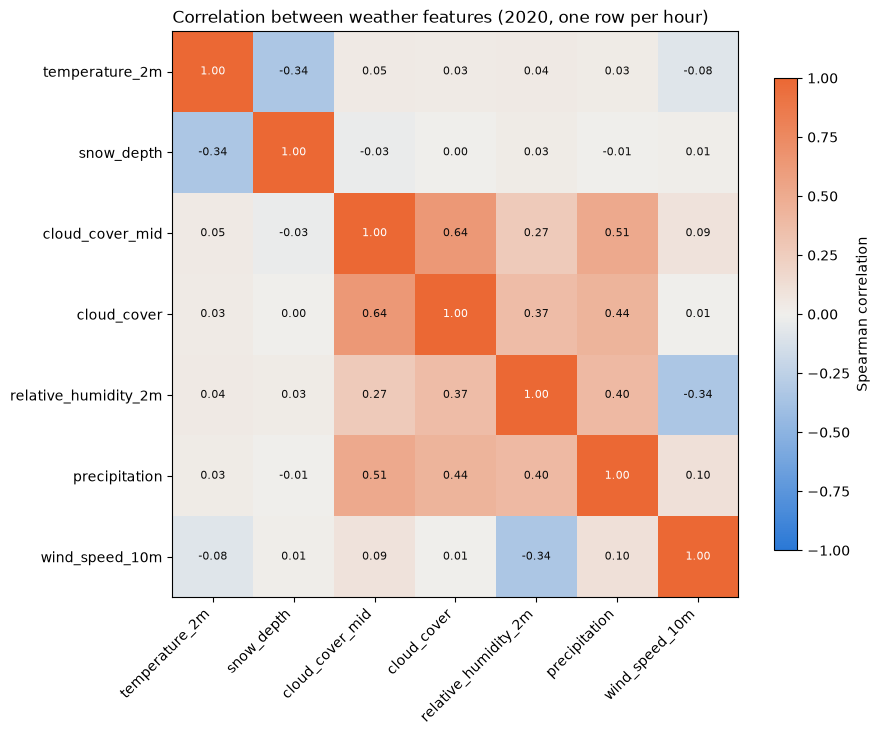

In [5]:
# Rerun Spearman correlation (rank-based), since several features are skewed or mostly zero
correlation = hourly_df[weather_cols].corr(method = 'spearman')

# blue = negative, grey = no relationship, orange = positive
diverging = LinearSegmentedColormap.from_list('diverging', ['#2a78d6', '#f0efec', '#eb6834'])

fig, ax = plt.subplots(figsize = (9, 7.5))
image = ax.imshow(correlation, cmap = diverging, vmin = -1, vmax = 1)
ax.set_xticks(range(len(weather_cols)), weather_cols, rotation = 45, ha = 'right')
ax.set_yticks(range(len(weather_cols)), weather_cols)
for i in range(len(weather_cols)):
    for j in range(len(weather_cols)):
        value = correlation.iloc[i, j]
        ax.text(j, i, f'{value:.2f}', ha = 'center', va = 'center', fontsize = 8,
                color = 'white' if abs(value) > 0.7 else '#0b0b0b')
fig.colorbar(image, ax = ax, shrink = 0.8, label = 'Spearman correlation')
ax.set_title('Correlation between weather features (2020, one row per hour)', loc = 'left')
plt.tight_layout()
plt.show()

### 2. Relevance to the target variable

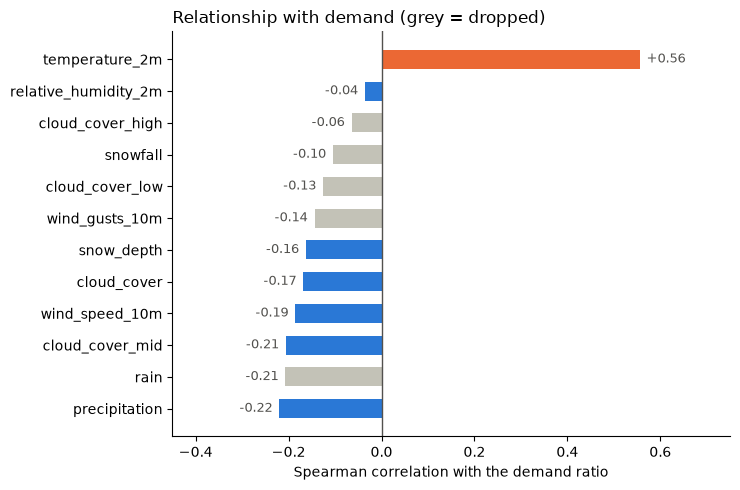

In [7]:
# demand changes a lot with the time of day and day of week, which would hide the effect of weather,
# so compare each hour's rentals with the usual level for that hour and weekday:
# demand ratio = rentals in this hour / average rentals for the same hour and weekday in 2020
# (1 = a normal hour, 0.5 = half the usual rentals)
usual_rentals = hourly_df.groupby([HOUR_OF_DAY, DAY_OF_WEEK])[Y_column].transform('mean')
hourly_df['demand_ratio'] = hourly_df[Y_column] / usual_rentals.replace(0, float('nan'))

# correlation of every weather feature (kept and dropped) with the demand ratio
all_weather_cols = weather_cols + dropped_columns
relevance = hourly_df[all_weather_cols].corrwith(hourly_df['demand_ratio'], method = 'spearman').sort_values()

fig, ax = plt.subplots(figsize = (7.5, 5))
bar_colours = ['#c3c2b7' if col in dropped_columns else ('#eb6834' if value > 0 else '#2a78d6')
               for col, value in relevance.items()]
ax.barh(relevance.index, relevance.values, color = bar_colours, height = 0.6)
ax.axvline(0, color = '#52514e', linewidth = 1)
for y, value in enumerate(relevance.values):
    ax.text(value + (0.015 if value > 0 else -0.015), y, f'{value:+.2f}', va = 'center',
            ha = 'left' if value > 0 else 'right', fontsize = 9, color = '#52514e')
ax.set_xlim(-0.45, 0.75)
ax.set_xlabel('Spearman correlation with the demand ratio')
ax.set_title('Relationship with demand (grey = dropped)', loc = 'left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### Conclusion

There are no more features to drop:
- No more duplicates: The strongest correlation left between two features is 0.64 (`cloud_cover` and `cloud_cover_mid`), far below the near-duplicate pairs we removed. Each kept feature carries information the others do not.
- The kept features are related to demand in the expected direction.
- Each kept feature is more related to demand than the feature it replaced: (e.g. `precipitation` over `rain`, `wind_speed_10m` over `wind_gusts_10m`, `cloud_cover_mid` over the low and high layers), so the reduced set loses little.
- `relative_humidity_2m` is the one exception: on its own it is barely related to demand. We keep it because it does not duplicate any other feature, and humidity may matter in combination with other features, which a single correlation cannot show but models may learn. 